# Project: Facial Recognition  
### Soren Patel

**AI Usage Statement:** I used AI in this lab for the image preprocessing function. I needed to know how to inspect image metadata and convert iPhone portrait pictures to a usable format.

## Imports and Setup

Import all necessary libraries for file reading, image processing, and neural network. Confirm either GPU or CPU as processing unit. Setup MTCNN for single-face extraction and InceptionResnetV1 for embeddings.

In [1]:
import os
import glob
from pathlib import Path
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from facenet_pytorch import MTCNN, InceptionResnetV1

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

mtcnn = MTCNN(image_size=160, margin=0, keep_all=False, device=device).eval()
resnet = InceptionResnetV1(pretrained='vggface2').eval().to(device)

Using device: cuda


## Functions and Gallery Definitions

Function to load and standardize image as well as feature extraction. Uses L2 normalization for cosine similarity.

In [2]:
def get_embedding(img_path):
    img = Image.open(img_path).convert('RGB')
    face = mtcnn(img)
    if face is None:
        return None
    face = face.unsqueeze(0).to(device)
    with torch.no_grad():
        emb = resnet(face)
        emb = F.normalize(emb, p=2, dim=1)
    return emb.squeeze(0).cpu()

Define image path and class alphas. Precompute embeddings and sort into 3 galleries: our class, all 2/C, and all images. Stack embeddings into tensors for fast matrix multiplication.

In [3]:
class_alphas = {'273126', '273480', '274260', '275262', '275352', '275580', '276516', '276546', '284932', '285094'}

gallery_paths = sorted(glob.glob('imgs/*.jpg'))

galleries = {
    'class': {'embs': [], 'alphas': [], 'paths': []},
    '2C': {'embs': [], 'alphas': [], 'paths': []},
    'all': {'embs': [], 'alphas': [], 'paths': []}
}

for path in gallery_paths:
    alpha = os.path.splitext(os.path.basename(path))[0]
    emb = get_embedding(path)
    
    if emb is not None:
        galleries['all']['embs'].append(emb)
        galleries['all']['alphas'].append(alpha)
        galleries['all']['paths'].append(path)
        
        if alpha.startswith('28'):
            galleries['2C']['embs'].append(emb)
            galleries['2C']['alphas'].append(alpha)
            galleries['2C']['paths'].append(path)
            
        if alpha in class_alphas:
            galleries['class']['embs'].append(emb)
            galleries['class']['alphas'].append(alpha)
            galleries['class']['paths'].append(path)

for g in galleries.values():
    if g['embs']:
        g['embs'] = torch.stack(g['embs'])

print(f"Loaded faces - Class: {len(galleries['class']['alphas'])}, 2/C: {len(galleries['2C']['alphas'])}, All: {len(galleries['all']['alphas'])}")

Loaded faces - Class: 10, 2/C: 1049, All: 3284


Function for feature extraction and face recognization. Picks the target gallery and performs matrix multiplication between the gallery matrix and probe image vector. Also computes indices of 5 highest scoring individuals. 

In [4]:
def recognize_face(probe_path, gallery_name='all'):
    probe_emb = get_embedding(probe_path)
    if probe_emb is None:
        print(f"Could not detect a face in {probe_path}")
        return

    g = galleries[gallery_name]
    k = min(5, len(g['alphas']))

    sims = torch.mv(g['embs'], probe_emb)
    top_scores, top_idx = torch.topk(sims, k=k)

    fig, axes = plt.subplots(1, k + 1, figsize=(15, 3))
    
    axes[0].imshow(Image.open(probe_path).convert('RGB'))
    axes[0].set_title(f"Probe\n{os.path.basename(probe_path)}")
    axes[0].axis('off')

    for i in range(k):
        match_idx = top_idx[i].item()
        match_img = Image.open(g['paths'][match_idx]).convert('RGB')
        
        axes[i + 1].imshow(match_img)
        axes[i + 1].set_title(f"#{i+1}: {g['alphas'][match_idx]}\nSim: {top_scores[i]:.2f}")
        axes[i + 1].axis('off')

    plt.suptitle(f"Matches in Gallery: {gallery_name.upper()}", fontsize=14)
    plt.tight_layout()
    plt.show()

Function for last bit of image preprocessing. Inxpects EXIF metadata and rotates portrait photos to have an upright face. Downscales large photos to a standardizes size. Passes the processed image to the MTCNN instance. Runs the probe vector across all three gallieries to observe ranking shifts and produce the output of top 5 ranking. 

In [7]:
def test_probe(img_path):
    raw_img = Image.open(img_path)
    probe_img = ImageOps.exif_transpose(raw_img).convert('RGB')
    probe_img.thumbnail((1024, 1024))

    face = mtcnn(probe_img)
    if face is None:
        print(f"Could not detect a face in {img_path}")
        return

    face_tensor = face.unsqueeze(0).to(device)
    with torch.no_grad():
        probe_emb = F.normalize(resnet(face_tensor), p=2, dim=1).squeeze(0).cpu()

    for g_name in ['class', '2C', 'all']:
        g = galleries[g_name]
        k = min(5, len(g['alphas']))
        sims = torch.mv(g['embs'], probe_emb)
        top_scores, top_idx = torch.topk(sims, k=k)

        fig, axes = plt.subplots(1, k + 1, figsize=(15, 3))
        axes[0].imshow(probe_img)
        axes[0].set_title(f"Probe\n{img_path}")
        axes[0].axis('off')

        for i in range(k):
            match_idx = top_idx[i].item()
            axes[i + 1].imshow(Image.open(g['paths'][match_idx]).convert('RGB'))
            axes[i + 1].set_title(f"#{i+1}: {g['alphas'][match_idx]}\nSim: {top_scores[i]:.2f}")
            axes[i + 1].axis('off')

        plt.suptitle(f"Matches in Gallery: {g_name.upper()}", fontsize=14)
        plt.tight_layout()
        plt.show()

## Probe Image Testing

### Image 1. Normal Face/Smile

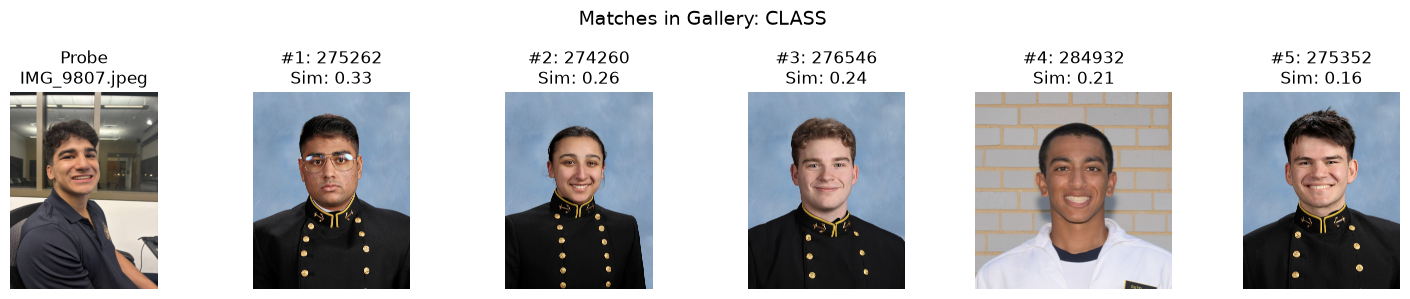

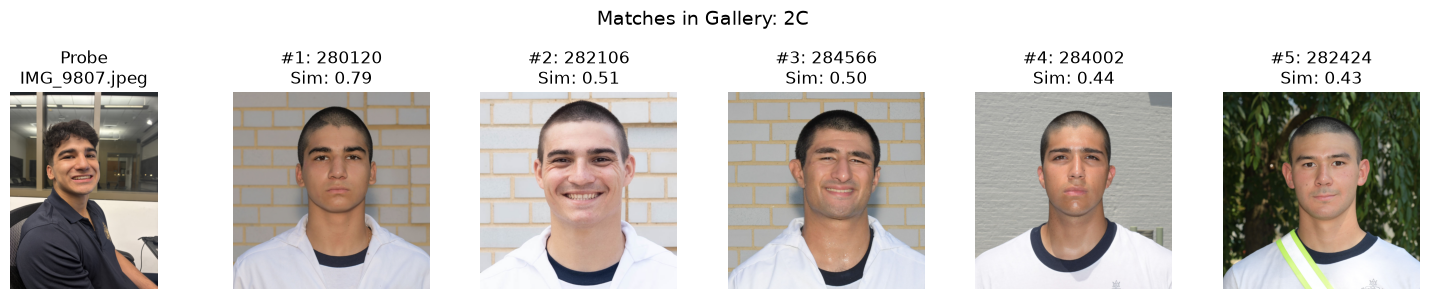

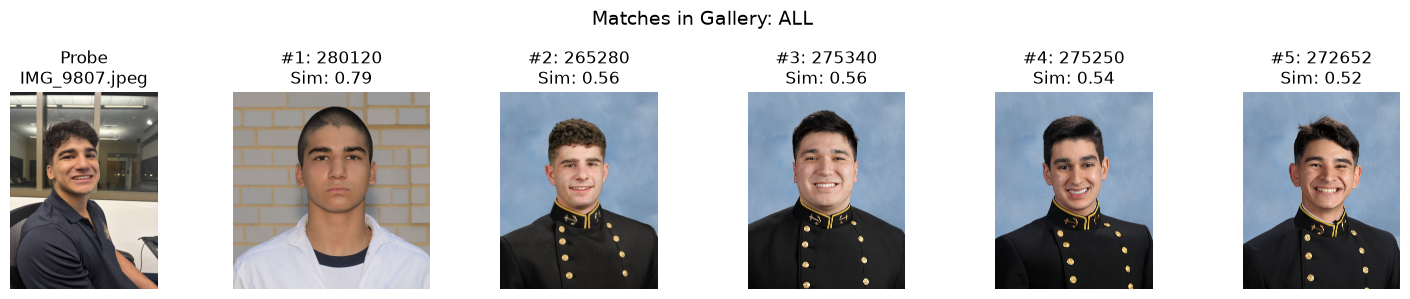

In [8]:
test_probe("IMG_9807.jpeg")

### Image 2. Hat

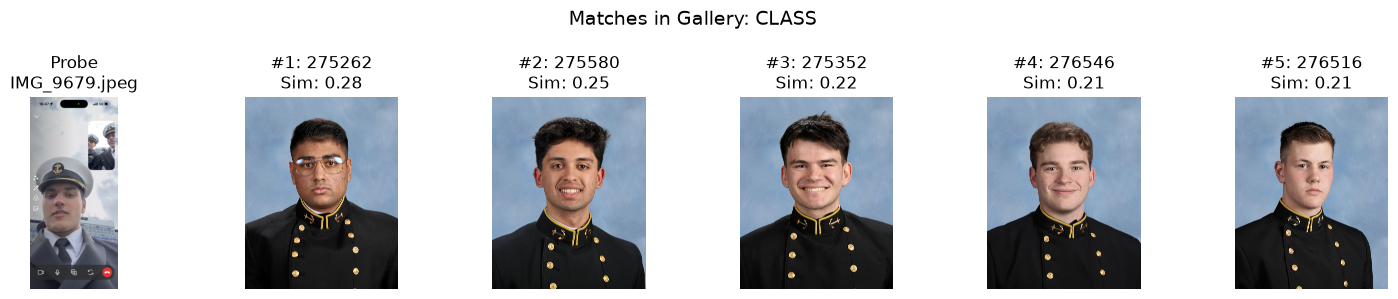

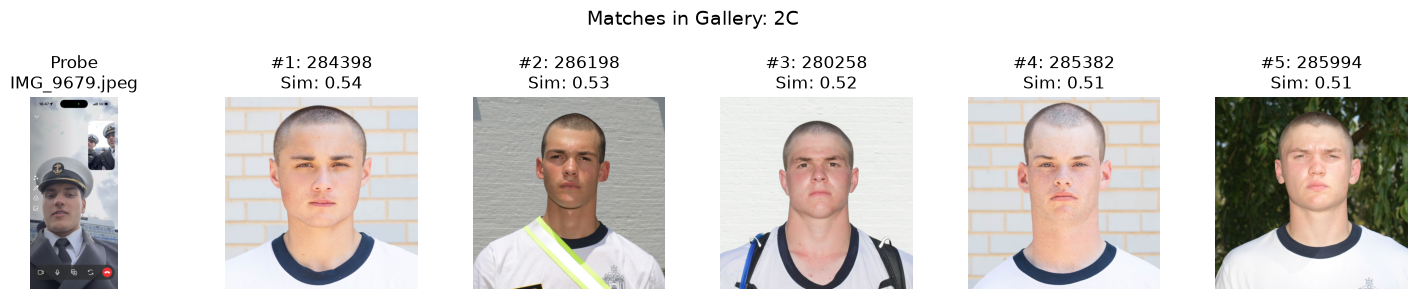

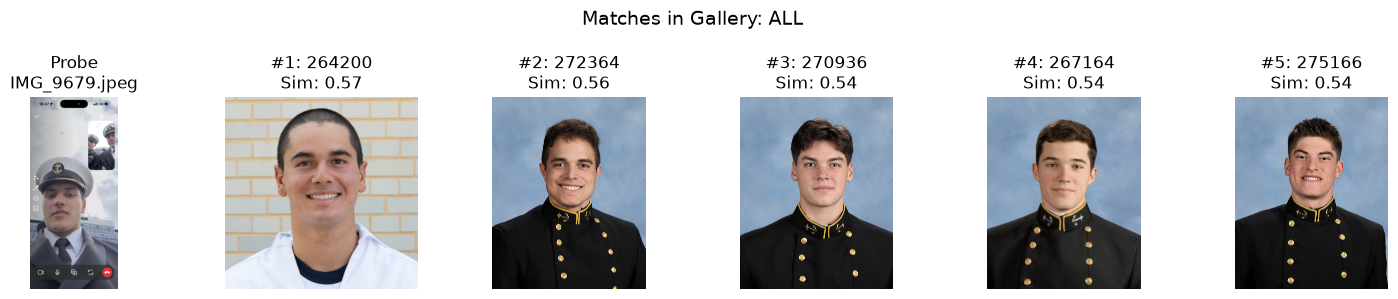

In [9]:
test_probe("IMG_9679.jpeg")

### Image 3. Sunglasses/Odd Lighting

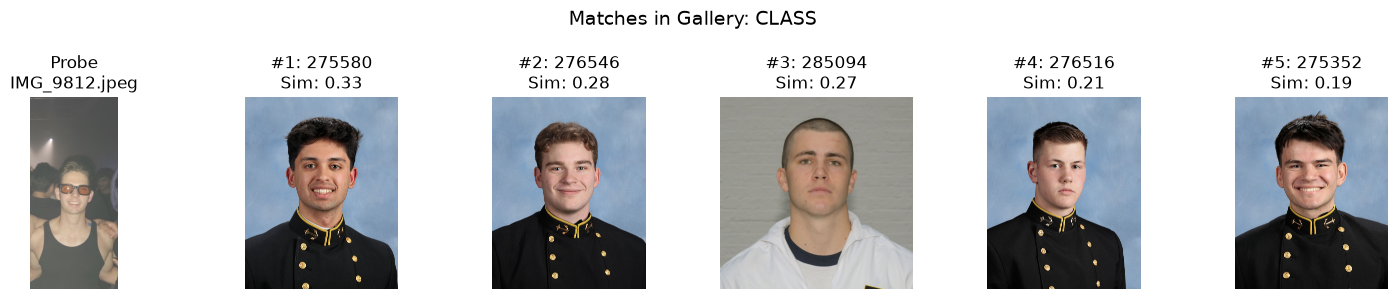

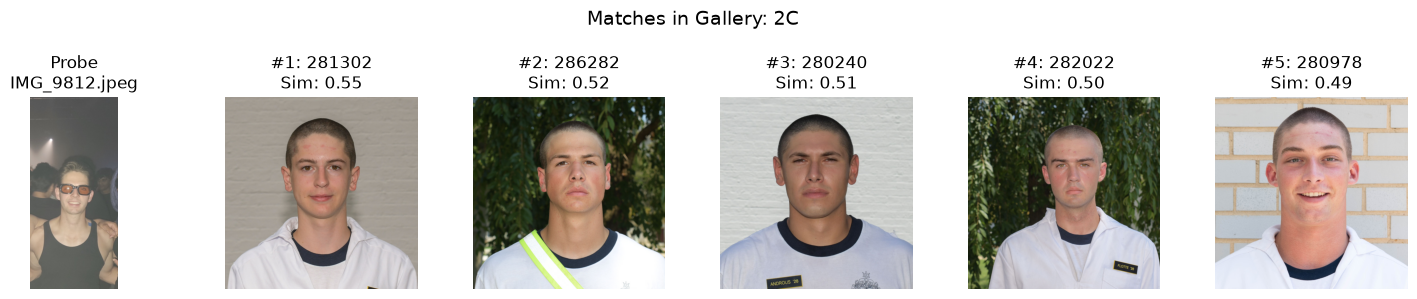

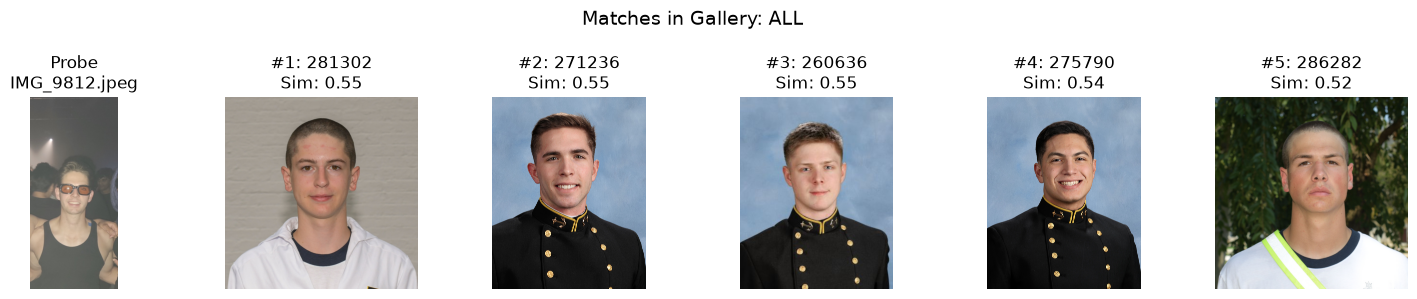

In [10]:
test_probe("IMG_9812.jpeg")

### Image 4. Sunglasses/Zoomed Out

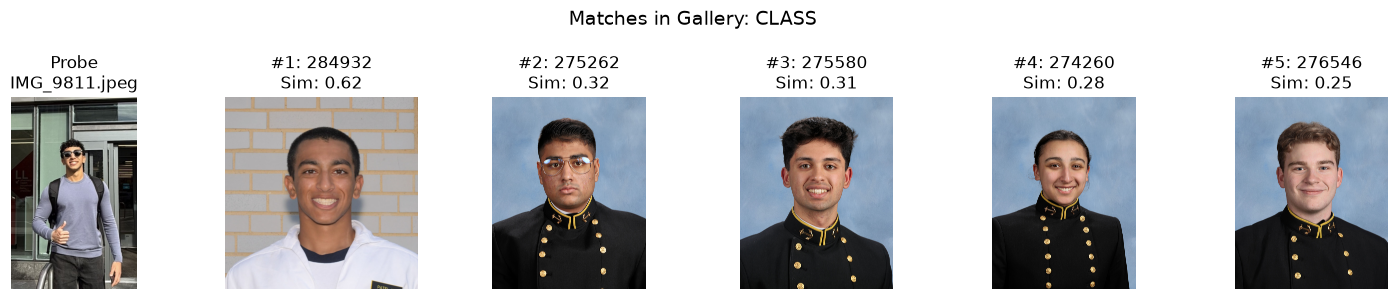

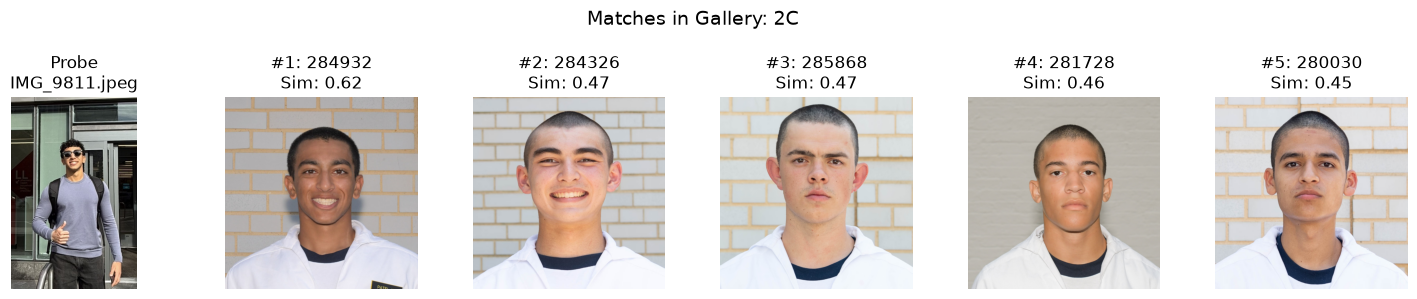

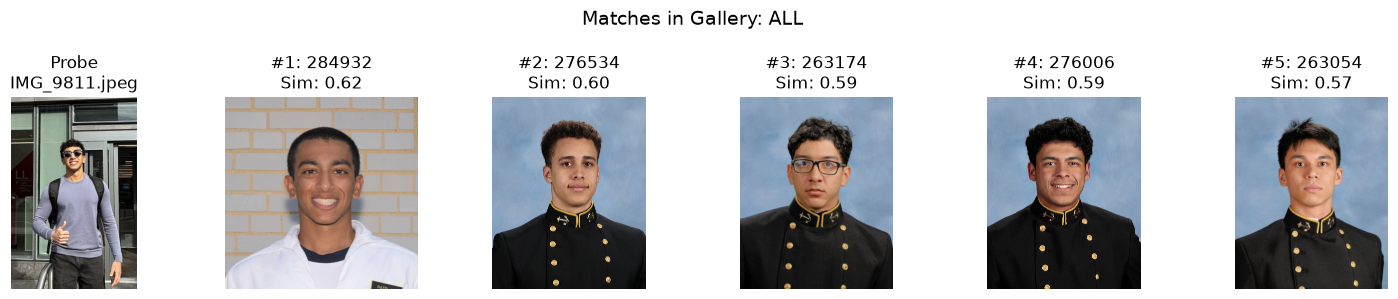

In [11]:
test_probe("IMG_9811.jpeg")

### Image 5. Age Difference

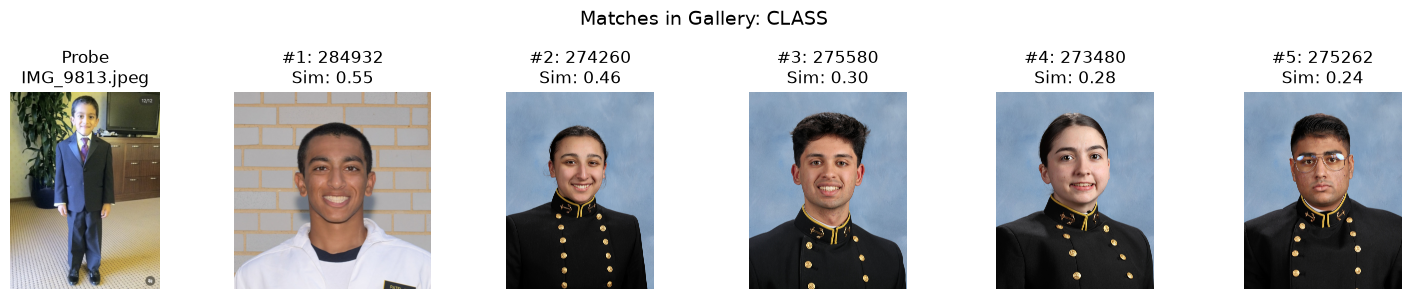

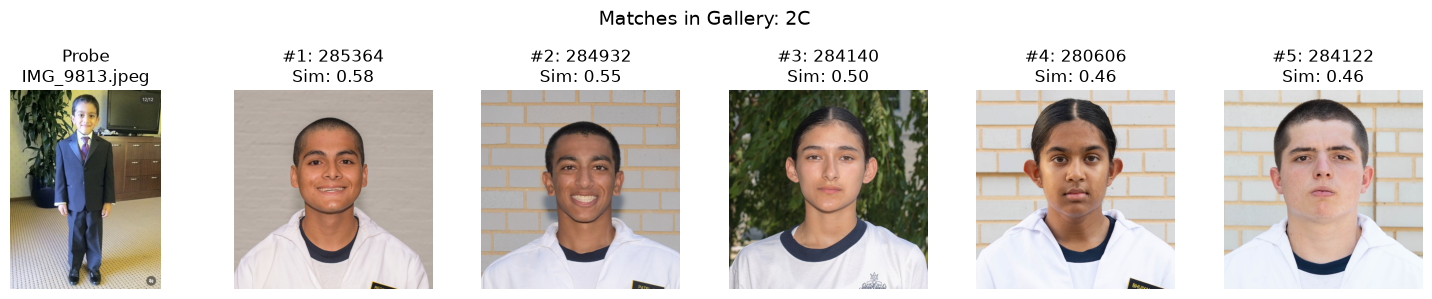

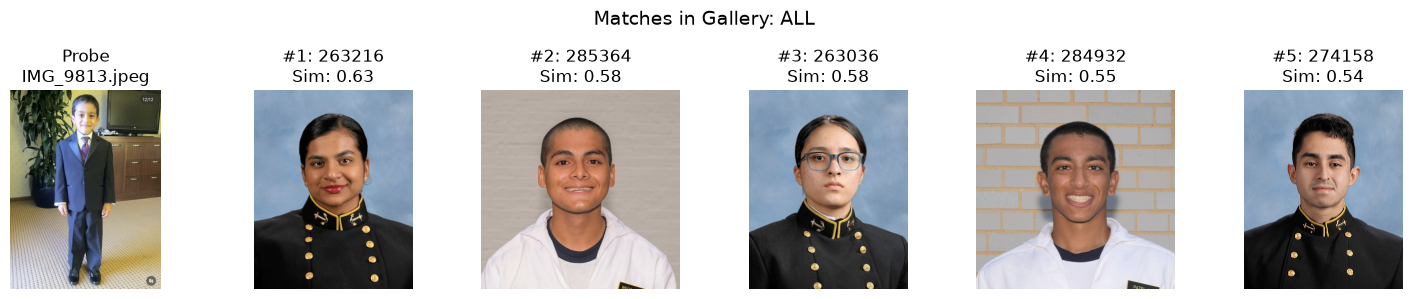

In [12]:
test_probe("IMG_9813.jpeg")

## Analysis  

I tested a variety of probe images, each with a different quality to be tested. Here is how they all resulted.  
1. Normal Image/Smile: The correct individual was identified both in the 2/C and All galleries. The image was clear and highlighted the features of the person.
2. Angled Picture/Hat: The correct individual was not identified. I believe this was because the photo was taken from below, and he also had on his cover. This hides some key facial features and distracts from the pure facial recognition.
3. Glasses/Bleached Lighting: The correct individual was not identified. I believe this was due to the very bright lighting of the picture, so the embedding vectors could not necessarily capture the perceived depth in the photo.
4. Sunglasses/Good Lighting: I was corerctly identified in the 2/C, All, and Class galleries. The image was clear, and the embeddings found enough similarity even with sunglasses on.
5. Young Photo: This is a young photo of me, and I wanted to see if it would recognize faces across an age gap. I was correctly identified in the Class gallery, but not in the other two galleries. However I was ranked in the top 5. This of course is due to the fact that facial structure changes over time in individuals.
  
  
For the images that did not correctly identify the correct person, the identified images were similar looking so the model was not very far off.